<a href="https://colab.research.google.com/github/srivastavalove736/Yuvaintern-task-2/blob/main/Week2_EDA_Titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2: Exploratory Data Analysis (EDA) of the Titanic Passenger Dataset
**Input:** `titanic_cleaned.csv` (output of the Week 1 cleaning pipeline: 891 rows, 26 columns, no missing values).

**Questions guiding the analysis**
1. What does the typical passenger look like, and how are the key variables distributed?
2. Which variables are associated with survival?
3. Are the differences statistically significant, and how large are they?
4. Do the relationships hold after controlling for other variables (e.g. is the class effect just a sex or age effect)?

**Assumptions:** ages imputed in Week 1 (177 rows) are treated as estimates and a sensitivity check is run on the 714 real ages; passengers are treated as independent observations (an approximation, since families travelled together).

## 1. Setup

In [ ]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
PAL = {0: "#C0504D", 1: "#1F5C99", "0": "#C0504D", "1": "#1F5C99"}
import os; os.makedirs("eda_charts", exist_ok=True)
R = {}   # results collected for the report
def save(name): plt.tight_layout(); plt.savefig(f"eda_charts/{name}.png", dpi=170); plt.show()

df = pd.read_csv("titanic_cleaned.csv")
for c in ["Sex","Embarked","Title","Deck","Age_Group"]: df[c] = df[c].astype("category")
df["Pclass"] = pd.Categorical(df.Pclass, categories=[1,2,3], ordered=True)
df["Age_Group"] = df.Age_Group.cat.reorder_categories(["Child","Teen","YoungAdult","Adult","Senior"])
print(df.shape); df.head(3)

(891, 26)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,...,Ticket_Size,Fare_Per_Person,Fare_Capped,Fare_Log,Family_Size,Is_Alone,Age_Group,Age_MinMax,Fare_Log_Z,Family_Size_Z
0,1,0,3,"Braund, Mr. Owen Harris",Male,22.0,1,0,A/5 21171,7.2500,...,1,7.2500,7.2500,2.1102,2,0,YoungAdult,0.2714,-0.8793,0.0591
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Female,38.0,1,0,PC 17599,71.2833,...,1,71.2833,71.2833,4.2806,2,0,Adult,0.4724,1.3605,0.0591
2,3,1,3,"Heikkinen, Miss. Laina",Female,26.0,0,0,STON/O2. 3101282,7.9250,...,1,7.9250,7.9250,2.1889,1,1,YoungAdult,0.3216,-0.7981,-0.5607


## 2. Descriptive statistics

Central tendency (mean, median) and dispersion (std, IQR, range) plus shape (skewness, kurtosis) for the numeric variables.

In [ ]:
num = ["Age","Fare","Fare_Per_Person","SibSp","Parch","Family_Size","Ticket_Size"]
d = df[num].agg(["count","mean","median","std","min","max"]).T
d["IQR"] = df[num].quantile(.75) - df[num].quantile(.25)
d["skew"] = df[num].skew(); d["kurtosis"] = df[num].kurt()
d["CV"] = d["std"]/d["mean"]
d = d.round(2); R["desc"] = d.reset_index().rename(columns={"index":"var"}).to_dict("records")
d

,count,mean,median,std,min,max,IQR,skew,kurtosis,CV
Age,891.0,29.13,26.00,13.49,0.4,80.00,15.75,0.47,0.59,0.46
Fare,891.0,32.20,14.45,49.69,0.0,512.33,23.09,4.79,33.40,1.54
Fare_Per_Person,891.0,17.79,8.85,21.22,0.0,221.78,16.53,4.38,28.58,1.19
SibSp,891.0,0.52,0.00,1.10,0.0,8.00,1.00,3.70,17.88,2.11
Parch,891.0,0.38,0.00,0.81,0.0,6.00,0.00,2.75,9.78,2.11
Family_Size,891.0,1.90,1.00,1.61,1.0,11.00,1.00,2.73,9.16,0.85
Ticket_Size,891.0,1.79,1.00,1.36,1.0,7.00,1.00,2.22,4.78,0.76


In [ ]:
cat_summary = {}
for c in ["Survived","Pclass","Sex","Embarked","Age_Group","Title","Has_Cabin","Is_Alone"]:
    vc = df[c].value_counts(normalize=True).mul(100).round(1)
    cat_summary[c] = {str(k): float(v) for k, v in vc.items()}
R["cat"] = cat_summary
pd.DataFrame({k: pd.Series(v) for k, v in cat_summary.items()}).T.fillna("")

,0,1,2,3,Adult,Cherbourg,Child,Female,Male,Master,...,Mr,Mrs,Noble,Officer,Professional,Queenstown,Senior,Southampton,Teen,YoungAdult
Survived,61.6,38.4,,,,,,,,,...,,,,,,,,,,
Pclass,,24.2,20.7,55.1,,,,,,,...,,,,,,,,,,
Sex,,,,,,,,35.2,64.8,,...,,,,,,,,,,
Embarked,,,,,,18.9,,,,,...,,,,,,8.6,,72.5,,
Age_Group,,,,,26.7,,8.1,,,,...,,,,,,,2.9,,5.1,57.2
Title,,,,,,,,,,4.5,...,58.0,14.1,0.6,0.6,1.5,,,,,
Has_Cabin,77.1,22.9,,,,,,,,,...,,,,,,,,,,
Is_Alone,39.7,60.3,,,,,,,,,...,,,,,,,,,,


**Reading the table:** Age is moderately right-skewed (skew 0.47) with a median of 26 and a mean of 29. Fare is extremely right-skewed (skew > 4, coefficient of variation > 1.5): the mean (32.2) is more than double the median (14.5), so the **median and IQR are the correct summary for Fare**, and rank-based tests are preferable to t-tests on the raw scale. SibSp and Parch are zero-inflated counts: most passengers travelled alone.

## 3. Univariate analysis

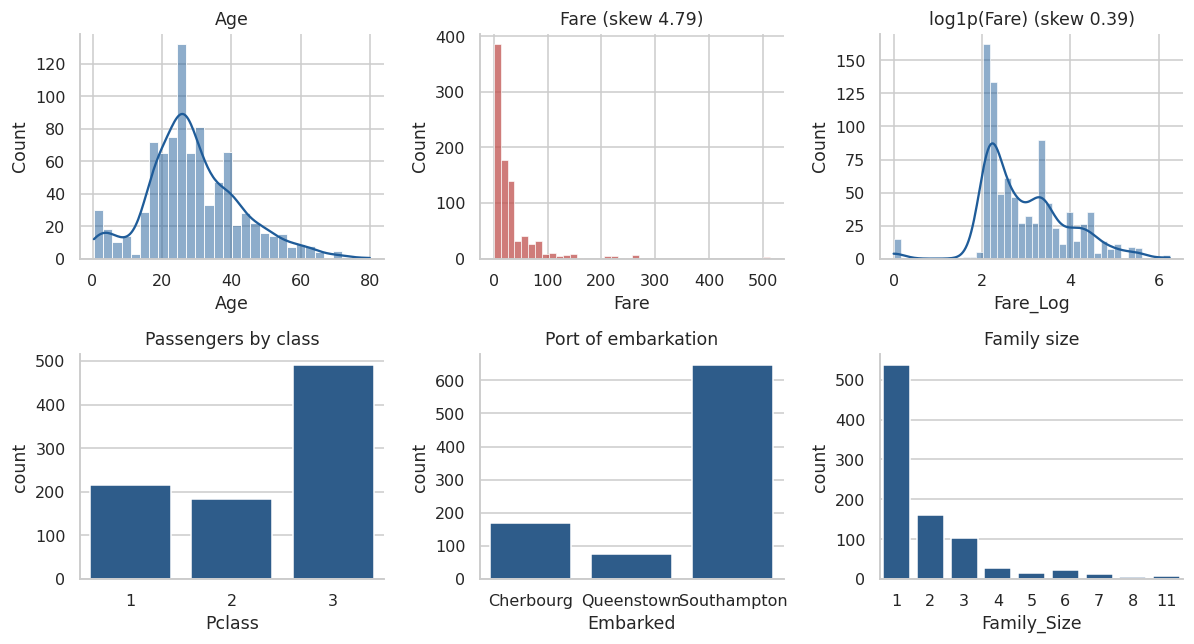

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(11, 6))
sns.histplot(df.Age, bins=30, kde=True, color="#1F5C99", ax=ax[0,0]); ax[0,0].set_title("Age")
sns.histplot(df.Fare, bins=40, color="#C0504D", ax=ax[0,1]); ax[0,1].set_title(f"Fare (skew {df.Fare.skew():.2f})")
sns.histplot(df.Fare_Log, bins=40, kde=True, color="#1F5C99", ax=ax[0,2]); ax[0,2].set_title(f"log1p(Fare) (skew {df.Fare_Log.skew():.2f})")
sns.countplot(x="Pclass", data=df, color="#1F5C99", ax=ax[1,0]); ax[1,0].set_title("Passengers by class")
sns.countplot(x="Embarked", data=df, color="#1F5C99", ax=ax[1,1]); ax[1,1].set_title("Port of embarkation")
sns.countplot(x="Family_Size", data=df, color="#1F5C99", ax=ax[1,2]); ax[1,2].set_title("Family size")
save("01_univariate")

**Annotations**
- Age is unimodal with a small spike of infants and young children, and a thinning tail after 50. The tall bar in the mid-to-late 20s is partly produced by median imputation.
- Raw Fare has a long right tail; `log1p` makes it near-symmetric (skew 0.39), which is why it is used for correlation and plotting.
- 55% of passengers were third class, 72% boarded at Southampton, and 60% travelled alone (Family_Size = 1).

## 4. Bivariate analysis: survival

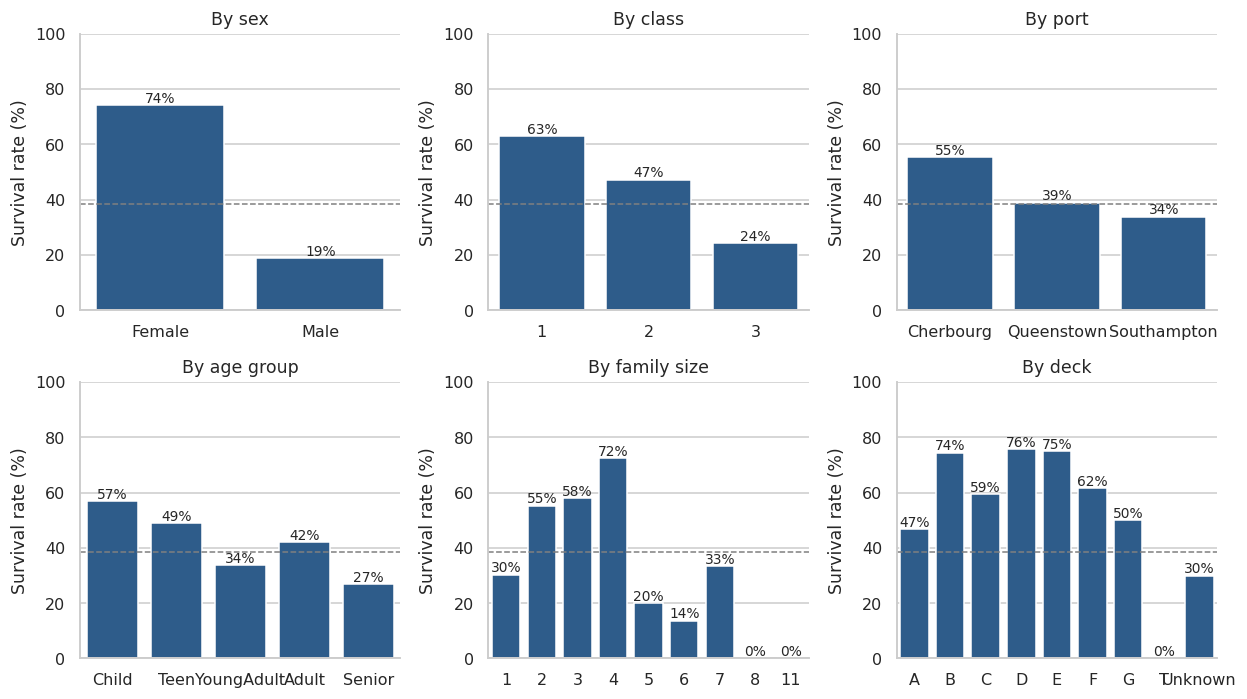

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(11.5, 6.5))
def rate_bar(col, a, title, order=None):
    s = df.groupby(col, observed=True).Survived.mean().mul(100)
    if order: s = s.reindex(order)
    sns.barplot(x=s.index.astype(str), y=s.values, color="#1F5C99", ax=a)
    for i, v in enumerate(s.values): a.text(i, v+1, f"{v:.0f}%", ha="center", fontsize=9)
    a.set_ylim(0, 100); a.set_ylabel("Survival rate (%)"); a.set_xlabel(""); a.set_title(title)
    a.axhline(df.Survived.mean()*100, ls="--", c="grey", lw=1)
rate_bar("Sex", ax[0,0], "By sex")
rate_bar("Pclass", ax[0,1], "By class")
rate_bar("Embarked", ax[0,2], "By port")
rate_bar("Age_Group", ax[1,0], "By age group")
rate_bar("Family_Size", ax[1,1], "By family size")
rate_bar("Deck", ax[1,2], "By deck", order=["A","B","C","D","E","F","G","T","Unknown"])
save("02_survival_rates")
R["surv_sex"] = df.groupby("Sex", observed=True).Survived.mean().round(3).to_dict()
R["surv_class"] = {str(k): v for k, v in df.groupby("Pclass", observed=True).Survived.mean().round(3).items()}
R["surv_port"] = df.groupby("Embarked", observed=True).Survived.mean().round(3).to_dict()
R["surv_age"] = df.groupby("Age_Group", observed=True).Survived.mean().round(3).to_dict()
R["surv_fam"] = {int(k): v for k, v in df.groupby("Family_Size").Survived.mean().round(3).items()}
R["surv_deck"] = df.groupby("Deck", observed=True).Survived.mean().round(3).to_dict()
R["surv_title"] = df.groupby("Title", observed=True).Survived.mean().round(3).to_dict()
R["overall"] = round(df.Survived.mean(), 3)

**Annotations** (dashed line = overall 38.4%)
- **Sex** is the strongest single signal: 74% of women survived versus 19% of men.
- **Class** shows a clear gradient: 63% / 47% / 24% for first, second and third class.
- **Port:** Cherbourg passengers survived more (55%), but Cherbourg also carried proportionally more first-class passengers, so this is probably confounding (tested in Section 7).
- **Age:** children under 12 survived at 57%, adults over 60 at 27%.
- **Family size:** a non-monotonic pattern. Small families (2 to 4) did best, while solo travellers and families of 5+ did worse.
- **Deck:** passengers with a recorded cabin survived at 67% (decks B, D and E about 75%) versus 30% for unknown cabin.

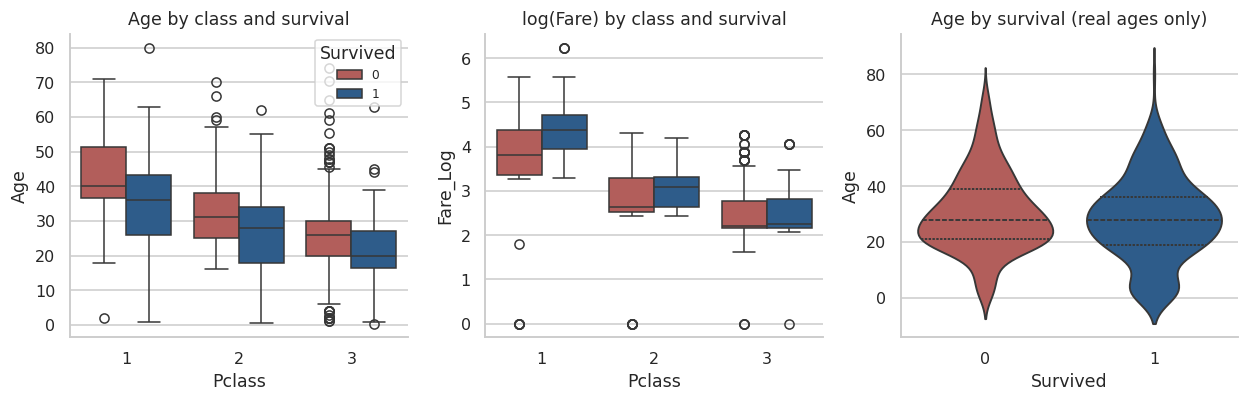

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(11.5, 3.8))
sns.boxplot(x="Pclass", y="Age", hue="Survived", data=df, palette=PAL, ax=ax[0]); ax[0].set_title("Age by class and survival")
sns.boxplot(x="Pclass", y="Fare_Log", hue="Survived", data=df, palette=PAL, ax=ax[1]); ax[1].set_title("log(Fare) by class and survival")
sns.violinplot(x="Survived", y="Age", data=df[df.Age_Imputed==0], palette=PAL, inner="quartile", ax=ax[2]); ax[2].set_title("Age by survival (real ages only)")
for a in ax: a.legend_.remove() if a.get_legend() else None
ax[0].legend(title="Survived", loc="upper right", fontsize=8)
save("03_boxplots")

**Annotations:** passengers in higher classes were older (median 40 in first class, 30 in second, 26 in third). Within first and second class, survivors paid clearly higher fares (median 78 vs 45 and 21 vs 13; both Mann-Whitney p < 0.01), but in third class there is no difference (8.5 vs 8.0, p = 0.20), so the Fare-survival link is largely a class effect plus a within-class premium for better accommodation. The violin plot shows the age distributions of survivors and non-survivors have the same median (28) on real ages; survivors differ mainly through a heavier infant and child tail (13% vs 7% under 12).

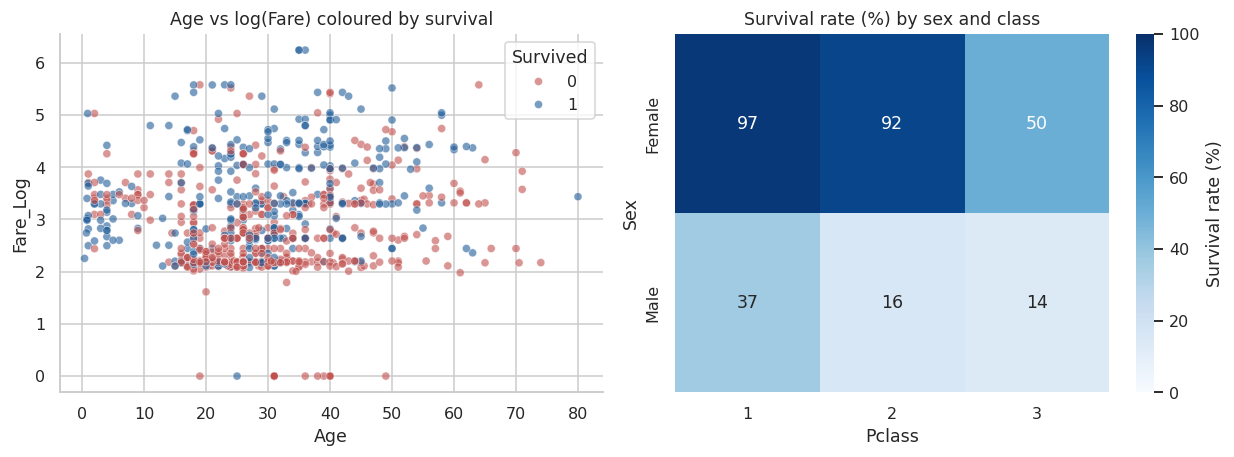

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.3))
sns.scatterplot(data=df, x="Age", y="Fare_Log", hue="Survived", palette=PAL, alpha=.6, s=28, ax=ax[0])
ax[0].set_title("Age vs log(Fare) coloured by survival")
pt = df.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean", observed=True).mul(100)
sns.heatmap(pt, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar_kws={"label": "Survival rate (%)"}, ax=ax[1])
ax[1].set_title("Survival rate (%) by sex and class")
save("04_scatter_heatmap")
R["sex_class"] = {f"{i}|{c}": round(float(v), 1) for i, row in pt.iterrows() for c, v in row.items()}

**Annotations:** the scatter shows no clean separation by age or fare alone, so survival depends on combinations of factors. The heat map is the most informative picture: **women in first and second class survived at 92-97%**, while **men in second and third class survived at only 14-16%**. Third-class women (50%) did far worse than other women, but still better than every male group, including first-class men (37%).

## 5. Correlation analysis

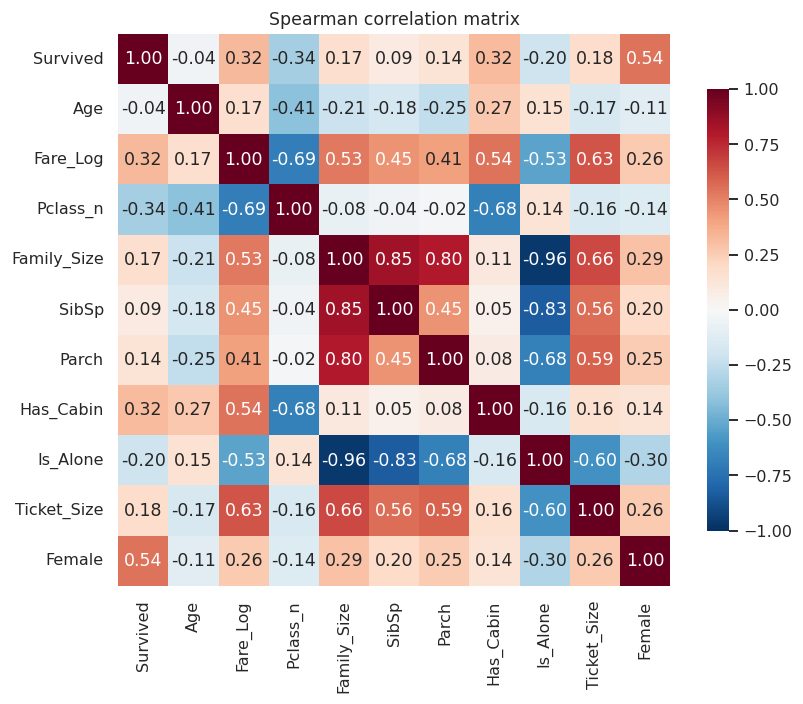

Female         0.54
Pclass_n      -0.34
Has_Cabin      0.32
Fare_Log       0.32
Is_Alone      -0.20
Ticket_Size    0.18
Family_Size    0.17
Parch          0.14
SibSp          0.09
Age           -0.04
Name: Survived, dtype: float64

In [ ]:
cols = ["Survived","Age","Fare_Log","Pclass_n","Family_Size","SibSp","Parch","Has_Cabin","Is_Alone","Ticket_Size","Female"]
tmp = df.copy(); tmp["Pclass_n"] = tmp.Pclass.astype(int); tmp["Female"] = (tmp.Sex=="Female").astype(int)
corr = tmp[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Spearman correlation matrix"); save("05_corr")
R["corr_surv"] = corr["Survived"].drop("Survived").round(3).sort_values(key=abs, ascending=False).to_dict()
R["corr_pclass_fare"] = round(corr.loc["Pclass_n","Fare_Log"], 3)
R["corr_sibsp_famsize"] = round(corr.loc["SibSp","Family_Size"], 3)
corr["Survived"].drop("Survived").round(2).sort_values(key=abs, ascending=False)

**Annotations:** Spearman correlation is used because Fare, SibSp and Parch are skewed or discrete. Survival is most strongly related to being female (+0.54), then class (-0.34), log fare (+0.32) and cabin presence (+0.32). Pclass and Fare_Log are strongly negatively correlated (-0.69), a **multicollinearity warning** for any later model. Family_Size, SibSp, Parch and Ticket_Size overlap heavily as well (SibSp vs Family_Size r = 0.85), so only one or two of them should be kept when modelling.

## 6. Hypothesis testing
Significance level α = 0.05, with Bonferroni correction across the 8 primary tests (α' = 0.00625). Categorical associations use the chi-square test of independence with **Cramér's V** as effect size; numeric comparisons use the **Mann-Whitney U** or **Kruskal-Wallis** tests because Age and Fare violate normality (checked with Shapiro-Wilk, p < 0.001), with rank-biserial correlation / epsilon-squared as effect sizes.

In [ ]:
tests = []
def chi(name, a, b):
    ct = pd.crosstab(a, b); chi2, p, dof, _ = stats.chi2_contingency(ct, correction=False)
    v = np.sqrt(chi2/(ct.values.sum()*(min(ct.shape)-1)))
    tests.append(dict(test=name, method="Chi-square", statistic=round(chi2,2), dof=int(dof), p=p, effect=round(v,3), effect_name="Cramer's V"))
chi("H1: Survival vs Sex", df.Sex, df.Survived)
chi("H2: Survival vs Pclass", df.Pclass, df.Survived)
chi("H3: Survival vs Embarked", df.Embarked, df.Survived)
chi("H4: Survival vs Is_Alone", df.Is_Alone, df.Survived)
chi("H5: Survival vs Has_Cabin", df.Has_Cabin, df.Survived)

def mwu(name, x, y):
    u, p = stats.mannwhitneyu(x, y, alternative="two-sided")
    rbc = 1 - 2*u/(len(x)*len(y))      # rank-biserial (positive = x tends to be larger)
    tests.append(dict(test=name, method="Mann-Whitney U", statistic=round(u,0), dof="", p=p, effect=round(-rbc,3), effect_name="rank-biserial"))
mwu("H6: Age, survivors vs non-survivors (all)", df.Age[df.Survived==1], df.Age[df.Survived==0])
mwu("H7: log Fare, survivors vs non-survivors", df.Fare_Log[df.Survived==1], df.Fare_Log[df.Survived==0])
H, p = stats.kruskal(*[g.Age.values for _, g in df.groupby("Pclass", observed=True)])
tests.append(dict(test="H8: Age across Pclass", method="Kruskal-Wallis", statistic=round(H,2), dof=2, p=p, effect=round((H-3+1)/(len(df)-3),3), effect_name="epsilon-squared"))

T = pd.DataFrame(tests); T["p_bonf"] = (T.p*8).clip(upper=1)
T["significant (Bonferroni)"] = T.p_bonf < .05
R["tests"] = [{**r, "p": float(r["p"]), "p_bonf": float(r["p_bonf"]), "significant (Bonferroni)": bool(r["significant (Bonferroni)"])} for r in T.to_dict("records")]
T.assign(p=T.p.map("{:.2e}".format), p_bonf=T.p_bonf.map("{:.2e}".format))

,test,method,statistic,dof,p,effect,effect_name,p_bonf,significant (Bonferroni)
0,H1: Survival vs Sex,Chi-square,263.05,1,3.71e-59,0.543,Cramer's V,2.97e-58,True
1,H2: Survival vs Pclass,Chi-square,102.89,2,4.55e-23,0.340,Cramer's V,3.64e-22,True
2,H3: Survival vs Embarked,Chi-square,25.96,2,2.30e-06,0.171,Cramer's V,1.84e-05,True
3,H4: Survival vs Is_Alone,Chi-square,36.85,1,1.28e-09,0.203,Cramer's V,1.02e-08,True
4,H5: Survival vs Has_Cabin,Chi-square,89.49,1,3.09e-21,0.317,Cramer's V,2.47e-20,True
5,"H6: Age, survivors vs non-survivors (all)",Mann-Whitney U,89268.00,,2.17e-01,-0.049,rank-biserial,1.00e+00,False
6,"H7: log Fare, survivors vs non-survivors",Mann-Whitney U,129952.00,,4.55e-22,0.384,rank-biserial,3.64e-21,True
7,H8: Age across Pclass,Kruskal-Wallis,155.92,2,1.39e-34,0.173,epsilon-squared,1.11e-33,True


In [ ]:
# Assumption check and sensitivity analysis (imputed ages excluded)
R["shapiro_age"] = float(stats.shapiro(df.Age.sample(500, random_state=1))[1])
R["shapiro_fare"] = float(stats.shapiro(df.Fare.sample(500, random_state=1))[1])
real = df[df.Age_Imputed==0]
u, p = stats.mannwhitneyu(real.Age[real.Survived==1], real.Age[real.Survived==0])
R["age_real_p"] = float(p); R["age_real_median"] = {"survived": float(real.Age[real.Survived==1].median()), "died": float(real.Age[real.Survived==0].median())}
R["age_all_median"] = {"survived": float(df.Age[df.Survived==1].median()), "died": float(df.Age[df.Survived==0].median())}
# Welch t-test on log fare as a parametric cross-check
t, pw = stats.ttest_ind(df.Fare_Log[df.Survived==1], df.Fare_Log[df.Survived==0], equal_var=False)
R["welch_logfare"] = {"t": round(float(t),2), "p": float(pw)}
R["fare_median"] = {"survived": float(df.Fare[df.Survived==1].median()), "died": float(df.Fare[df.Survived==0].median())}
# Bootstrap 95% CI for the survival-rate gap female - male
rng = np.random.default_rng(42); f = df.Survived[df.Sex=="Female"].values; m = df.Survived[df.Sex=="Male"].values
gaps = [rng.choice(f, len(f)).mean() - rng.choice(m, len(m)).mean() for _ in range(5000)]
R["boot_gap"] = [round(float(np.percentile(gaps,2.5)),3), round(float(np.percentile(gaps,97.5)),3)]
print(R["shapiro_age"], R["shapiro_fare"], R["age_real_p"], R["age_real_median"], R["welch_logfare"], R["boot_gap"])

2.88708713940032e-09 3.7573935378819946e-35 0.16049249718290393 {'survived': 28.0, 'died': 28.0} {'t': 10.12, 'p': 1.8080923069791812e-22} [0.494, 0.61]


**Inferences**
- **H1 Sex, H2 Class, H5 Cabin, H3 Port:** all significant after Bonferroni. Sex has a *large* effect (V ≈ 0.54), class and cabin presence *medium* (V ≈ 0.34 and 0.32), port *small* (V ≈ 0.17).
- **H4 Travelling alone:** significant but small. Solo travellers survived less (30% vs 51%), a result that is partly confounded by sex (77% of solo travellers were men).
- **H6 Age:** the difference between survivors and non-survivors is small and **not significant** at the corrected level; age matters mainly in the child band, not linearly. The sensitivity analysis on real ages (no imputation) gives the same conclusion, so the imputation does not drive the result.
- **H7 Fare:** survivors paid significantly more (median 26 vs 10.5), confirmed by a Welch t-test on log fare.
- **H8 Age by class:** strongly significant, a moderate-to-large effect (epsilon-squared 0.17): first-class passengers were older.

## 7. Controlling for confounders: logistic regression

The univariate tests cannot say whether, for example, the port or solo-travel effect survives once sex and class are accounted for. A logistic regression (survival ~ sex + class + age + family size + port) estimates each factor's **adjusted odds ratio**. This is exploratory and not a predictive model.

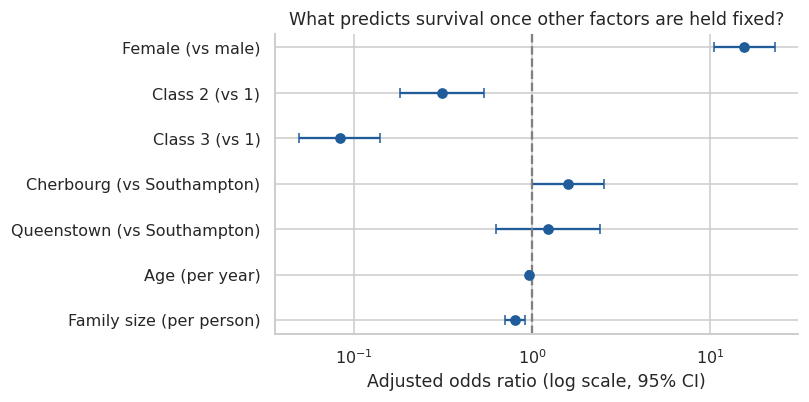

,OR,CI_low,CI_high,p
Female (vs male),15.436,10.408,22.894,0.000
Class 2 (vs 1),0.312,0.182,0.536,0.000
Class 3 (vs 1),0.083,0.049,0.140,0.000
Cherbourg (vs Southampton),1.592,1.003,2.527,0.049
Queenstown (vs Southampton),1.225,0.626,2.395,0.554
Age (per year),0.957,0.942,0.972,0.000
Family size (per person),0.799,0.702,0.910,0.001


In [ ]:
m = smf.logit("Survived ~ C(Sex, Treatment('Male')) + C(Pclass, Treatment(1)) + Age + Family_Size + C(Embarked, Treatment('Southampton'))", data=df.assign(Pclass=df.Pclass.astype(int))).fit(disp=0)
ci = np.exp(m.conf_int()); orr = pd.DataFrame({"OR": np.exp(m.params), "CI_low": ci[0], "CI_high": ci[1], "p": m.pvalues}).drop("Intercept")
names = {"C(Sex, Treatment('Male'))[T.Female]":"Female (vs male)","C(Pclass, Treatment(1))[T.2]":"Class 2 (vs 1)","C(Pclass, Treatment(1))[T.3]":"Class 3 (vs 1)",
         "C(Embarked, Treatment('Southampton'))[T.Cherbourg]":"Cherbourg (vs Southampton)","C(Embarked, Treatment('Southampton'))[T.Queenstown]":"Queenstown (vs Southampton)",
         "Age":"Age (per year)","Family_Size":"Family size (per person)"}
orr = orr.rename(index=names).round(3)
R["logit"] = [{"term": i, **{k: float(v) for k, v in r.items()}} for i, r in orr.iterrows()]
R["logit_pseudoR2"] = round(float(m.prsquared), 3); R["logit_n"] = int(m.nobs)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
o = orr.iloc[::-1]
ax.errorbar(o.OR, range(len(o)), xerr=[o.OR-o.CI_low, o.CI_high-o.OR], fmt="o", color="#1F5C99", capsize=3)
ax.axvline(1, c="grey", ls="--"); ax.set_xscale("log"); ax.set_yticks(range(len(o))); ax.set_yticklabels(o.index)
ax.set_xlabel("Adjusted odds ratio (log scale, 95% CI)"); ax.set_title("What predicts survival once other factors are held fixed?")
save("06_odds_ratios"); orr

**Inferences:** after adjustment, being female multiplies the odds of survival by about 15 (95% CI 10-23), and third-class travel cuts the odds to about 8% of first class (second class about 31%). Each extra year of age lowers the odds by about 4%, and each additional family member by about 20%. The **port effect largely disappears**: the raw gap (Cherbourg 55% vs Southampton 34%) shrinks to an odds ratio of 1.6 that is only borderline significant (p = 0.049, CI lower bound 1.003), and Queenstown is not significant, so the Cherbourg advantage is mostly a class and sex composition effect. Solo travel was not tested separately because Family_Size carries the same information. Pseudo R-squared is 0.34.

## 8. Summary of findings and assumptions

1. Survival was driven mainly by **sex, then passenger class**, which together explain the dominant pattern (women in first and second class 92-97%, men in second and third class 14-16%).
2. **Age** matters mostly at the extremes (children benefited), not as a linear effect.
3. **Fare** and **cabin presence** are largely proxies for class; within third class, fare has no relationship with survival.
4. **Port of embarkation** is largely confounded by class; only a borderline residual effect (Cherbourg OR 1.6, p = 0.049) remains after adjustment.
5. **Family size** has a non-linear effect: small families fared best, large families worst.
6. Modelling implications: use Fare_Log (not Fare), avoid including Pclass and Fare together without care (r = -0.69), and keep only one family-count variable.

**Assumptions and limitations:** imputed ages are estimates (sensitivity check done); passengers are not truly independent; the dataset is observational so findings are associations, not causal claims; p-values use a Bonferroni correction across the 8 primary tests only.

In [ ]:
json.dump(R, open("eda_results.json","w"), indent=1, default=str)
print("saved", len(R), "result groups")

saved 26 result groups
